# GVH Diagonal Cubic — CHH-INVERSE-02
## Hierarchical Hidden Subcube Recovery — benchmark synthétique reproductible

**Contrat scientifique enregistré avant l'évaluation : 18 novembre 2026**  
Identifiant : `GVH_CHH_INVERSE_02_Hierarchical_Hidden_Subcube_Recovery_FAST`

### Questions falsifiables

1. Un système ne comportant aucun corps caché est-il classé correctement ?
2. Un système comportant un corps caché est-il distingué d'un modèle sans corps ?
3. Deux corps séparés, mais invisibles, sont-ils détectés **comme deux** plutôt que comme un seul ?
4. Un sous-cube invisible composite contenant **deux corps rapprochés** est-il au contraire **indiscernable d'un corps effectif** avec les observations imposées ?
5. Si le premier corps a été **identifié indépendamment**, la soustraction de sa contribution permet-elle de reconstruire le second ?

### Séparation des opérations (strictement maintenue)

- **CHH — composition** : le cube global peut contenir un sous-cube $H$, lui-même composé de $H_1,H_2$. Ce n'est **pas** une dérivation des objets ni de leurs lois.
- **Dynamique directe de contrôle** : accélération gravitationnelle newtonienne, évaluée sur des **trajectoires circulaires de référence prescrites**. Ce ne sont **pas** des trajectoires $N$-corps intégrées ni des observations réelles.
- **Inférence inverse** : recherche de $N_H\in\{0,1,2\}$ corps cachés, paramètres $(m,a,\varphi)$, sélection sur l'entraînement seulement.

### Hypothèses et limites verrouillées

- Units : AU, année julienne, masse solaire ; $G=4\pi^2$ dans la normalisation képlérienne simplifiée.
- Trois corps témoins de masse négligeable suivent des orbites circulaires fixes autour d'une étoile centrale. Leurs **positions sont supposées connues**, et l'on simule des **résidus d'accélération** calculés aux positions prescrites. La rétroaction sur les trajectoires des témoins, l'effet gravitationnel des témoins sur les sources cachées, les autres planètes et la relativité sont ignorés.
- Observables : *résidus d'accélération*, non positions astrométriques directement mesurées ; **un véritable test observationnel nécessiterait un opérateur de mesure explicite** et une covariance instrumentale.
- Sources simples $H_i$ : masses ponctuelles sur orbites circulaires képlériennes indépendantes. Dans le cas de la binaire rapprochée, son mouvement interne est imposé selon une approximation hiérarchique — **ce générateur n'appartient pas exactement à la famille des modèles inverses**.
- $t_{\rm train}=0\ldots180\,\mathrm{ans}$, $t_{\rm test}=184\ldots252\,\mathrm{ans}$ : **les dates test ne participent ni à l'ajustement ni à la sélection des modèles**.
- Bruit gaussien indépendant : $\sigma=0.04$ unité numérique d'accélération ; graine déterministe 20261118. Aucune donnée ALMA, aucune observation réelle, aucune EOM dérivée de $S_{\rm cand}$.
- Classes modèles évaluées : $M_0$ (0 corps), $M_1$ (1 corps, 3 paramètres), $M_2$ (2 corps, 6 paramètres), orbites coplanaires circulaires. Sélection via $\mathrm{BIC}=\chi^2+k\ln N$ **sur les données d'entraînement** ; BIC utilisé comme diagnostic de pénalisation des paramètres, **pas** comme preuve d'existence d'une planète.
- Aucune sélection des seuils sur les dates réservées. Pas de preuve de nouvelle dynamique GVH par réussite de l'inférence.

**Références de méthode (physique et inférence établies, retrouvées via Scite) :**  
- https://doi.org/10.1111/j.1365-2966.2011.18962.x (modélisation et sélection de corps exoplanétaires)  
- https://doi.org/10.1051/0004-6361/202244633 (astrométrie, vitesses radiales et accélérations de compagnons)  
- https://doi.org/10.3847/2041-8213/ae42cd (dégénérescences entre solutions astrométriques simples et multiples, 2026).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import least_squares
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib

np.set_printoptions(precision=7, suppress=True)
RUN_NAME = 'GVH_CHH_INVERSE_02_Hierarchical_Hidden_Subcube_Recovery_FAST'
SEED = 20261118
G = 4 * np.pi**2  # AU^3 / (masse solaire * an_julien^2), normalisation synthétique
MASS_UNIT = 1e-5  # masses solaires : q=1 équivaut à 1e-5 M_Sun
AMPLITUDE_SCALE = 1e6  # l'accélération est exprimée en unités de 1e-6 AU/an^2
SIGMA = 0.04
AU_M = 149597870700.0
YR_S = 365.25 * 86400.0
ACC_UNIT_SI = 1e-6 * AU_M/YR_S**2
TRAIN_T = np.linspace(0,180,73)
TEST_T = np.linspace(184,252,35)
T = np.r_[TRAIN_T,TEST_T]
N_TRAIN = len(TRAIN_T)
PROBES = ((6.2,.3),(11.0,2.2),(16.0,4.5))  # (rayon en AU, phase en rad)

# Contrat : les paramètres cachés ne sont utilisés QUE pour générer les jeux de données et auditer les résultats.
H1_GENERATOR = (4.4,22.5,0.91)  # q, AU, rad
H2_GENERATOR = (7.3,34.8,3.40)
BINARY_GENERATOR = {'q1':4.8,'q2':5.2,'a':29.0,'phi':1.62,'d':.18,'phi_internal':.74}
MODEL_BOUNDS = ([0.,17.,0.],[16.,45.,2*np.pi])
GRID_RADII = np.linspace(18,44,80)
GRID_PHASES = np.linspace(0,2*np.pi,96,endpoint=False)

assert len(TRAIN_T)==73 and len(TEST_T)==35 and TRAIN_T[-1]<TEST_T[0]
assert ACC_UNIT_SI>0 and SIGMA>0
print('Contrat fixé : ',len(TRAIN_T),'dates TRAIN,',len(TEST_T),'dates TEST, sigma',SIGMA)
print('1 unité accélération = ',ACC_UNIT_SI,'m/s^2')

Contrat fixé :  73 dates TRAIN, 35 dates TEST, sigma 0.04
1 unité accélération =  1.5021644432825527e-10 m/s^2


## Niveau 1 — Composition CHH : un sous-cube invisible peut lui-même être composite

Nous écrivons $C_{\mathrm{sys}}=\mathcal A_\ell(C_1,C_2,C_3,H)$, tandis que $H=\mathcal A_{\ell'}(H_1,H_2)$ peut être non résolu.  
Le système global peut paraître contenir **un** sous-cube $H$ même si $H$ contient physiquement plusieurs composants. L'observation doit déterminer combien de paramètres internes sont **identifiables**, sans postuler d'avance leur existence.

## Niveau 2 — Physique établie : anomalie gravitationnelle sur orbites de référence

Pour chaque corps témoin $i$, dont la trajectoire $\mathbf r_i(t)$ est prescrite, la contribution des corps invisibles est

$$\Delta\mathbf a_i(t)=\sum_{h=1}^{N_H} Gm_h\frac{\mathbf r_h(t)-\mathbf r_i(t)}{|\mathbf r_h(t)-\mathbf r_i(t)|^3}. $$

La source simple a $\mathbf r_h(t)=a_h[\cos(\varphi_h+\sqrt{G/a_h^3}\,t),\sin(\varphi_h+\sqrt{G/a_h^3}\,t)]$.  
**Ce modèle est une approximation linéarisée de l'anomalie gravitationnelle sur trajectoires fixes** : il ne simule pas les perturbations orbitales auto-cohérentes des corps témoins.

In [2]:
def probe_positions(times):
    times = np.asarray(times,float)
    out = []
    for a,phase in PROBES:
        ang = phase + np.sqrt(G/a**3)*times
        out.append(a*np.stack([np.cos(ang),np.sin(ang)],axis=-1))
    return np.stack(out,axis=1)
P = probe_positions(T)

def single_source_basis(a,phi, times=T, positions=P):
    angle = phi + np.sqrt(G/a**3)*times
    source = a*np.stack([np.cos(angle),np.sin(angle)],axis=-1)
    dr=source[:,None,:]-positions
    rr=np.linalg.norm(dr,axis=-1)
    return (AMPLITUDE_SCALE*G*MASS_UNIT)*dr/(rr[:,:,None]**3)

def model_accel(parameters, times=T, positions=P):
    parameters=np.asarray(parameters,float)
    acc=np.zeros_like(positions)
    if parameters.size==0:return acc
    for q,a,phi in parameters.reshape(-1,3):
        acc += q*single_source_basis(a,phi,times,positions)
    return acc

def hierarchical_binary_accel(times=T, positions=P, b=BINARY_GENERATOR):
    q1,q2,a,phi,d=b['q1'],b['q2'],b['a'],b['phi'],b['d']
    n_outer=np.sqrt(G/a**3)
    n_internal=np.sqrt(G*MASS_UNIT*(q1+q2)/d**3)
    ang_outer=phi+n_outer*times
    center=a*np.stack([np.cos(ang_outer),np.sin(ang_outer)],axis=-1)
    ang_internal=b['phi_internal']+n_internal*times
    separation=d*np.stack([np.cos(ang_internal),np.sin(ang_internal)],axis=-1)
    r1=center-q2/(q1+q2)*separation
    r2=center+q1/(q1+q2)*separation
    def contribution(source, q):
        dr=source[:,None,:]-positions
        distance=np.linalg.norm(dr,axis=-1)
        return (AMPLITUDE_SCALE*G*MASS_UNIT*q)*dr/(distance[:,:,None]**3)
    return contribution(r1,q1)+contribution(r2,q2)

def rmse(a,b):return float(np.sqrt(np.mean((np.asarray(a)-np.asarray(b))**2)))
def ang_diff(a,b):return float(abs((a-b+np.pi)%(2*np.pi)-np.pi))

assert P.shape==(len(T),len(PROBES),2)
assert np.isfinite(model_accel(H1_GENERATOR)).all()
assert np.isfinite(hierarchical_binary_accel()).all()
print('Modèle direct synthétique vérifié : 3 sondes, champs de gravitation nouveaux uniquement.')

Modèle direct synthétique vérifié : 3 sondes, champs de gravitation nouveaux uniquement.


## Niveau 3 — Inversion pseudo-aveugle, modèles 0/1/2 sous-cubes

Les routines ci-dessous reçoivent **seulement les anomalies bruitées à l'entraînement**. Pour $k\geq1$, l'initialisation utilise une banque **prédéfinie** d'orbites circulaires ; une régression linéaire non négative estime une masse préliminaire pour chaque candidate, puis les trois paramètres sont affinés par moindres carrés non linéaires. 

Les paramètres du générateur restent séparés dans la cellule précédente et **ne sont jamais passés à l'algorithme d'ajustement**. La phase d'évaluation de la vérité et le test réservé apparaissent après la sélection par BIC.

In [3]:
# Banque de profils, construite uniquement à partir du contrat temporel/géométrique de l'entraînement.
PARAM_GRID=np.array([(a,phi) for a in GRID_RADII for phi in GRID_PHASES])
DESIGN=np.column_stack([
    single_source_basis(a,phi,TRAIN_T,P[:N_TRAIN]).ravel()
    for a,phi in PARAM_GRID
])
DESIGN_NORM2=np.einsum('ij,ij->j',DESIGN,DESIGN)
NOBS=2*len(PROBES)*N_TRAIN

# IMPORTANT : copie explicite ; le résidu de recherche ne peut pas muter les observations originales.
def greedy_initialization(train_obs,k):
    resid=np.asarray(train_obs[:N_TRAIN],float).ravel().copy()
    out=[]
    for _ in range(k):
        proj=DESIGN.T@resid
        masses=np.maximum(proj,0)/DESIGN_NORM2
        score=masses*proj
        idx=int(np.argmax(score))
        out.extend([float(masses[idx]),float(PARAM_GRID[idx,0]),float(PARAM_GRID[idx,1])])
        resid-=masses[idx]*DESIGN[:,idx]
    return np.asarray(out,float)

def fit_hidden_model(train_obs, k):
    before=np.asarray(train_obs).copy()
    if k==0:
        result={'parameters':[],'chi2_train':float(np.sum((before[:N_TRAIN]/SIGMA)**2)),
                'nfev':0,'success':True}
    else:
        start=greedy_initialization(before,k)
        lim_low,lim_high=MODEL_BOUNDS
        fit=least_squares(
            lambda params: ((model_accel(params,TRAIN_T,P[:N_TRAIN])-before[:N_TRAIN])/SIGMA).ravel(),
            start,bounds=(lim_low*k,lim_high*k),max_nfev=160,
            ftol=1e-10,xtol=1e-10,gtol=1e-10,method='trf')
        ordered=fit.x.reshape(-1,3)
        ordered=ordered[np.argsort(ordered[:,1])].reshape(-1)
        result={'parameters':ordered.tolist(),'chi2_train':float(2*fit.cost),
                'nfev':int(fit.nfev),'success':bool(fit.success),'initial':start.tolist()}
    result['k_hidden']=int(k)
    result['n_parameters']=3*k
    result['BIC_train']=float(result['chi2_train']+3*k*np.log(NOBS))
    assert np.array_equal(before,train_obs), 'Les observations d’entraînement ont été mutées !'
    return result

print('Banque de recherche :',len(PARAM_GRID),'candidats ; données TRAIN :',NOBS,'composantes')

Banque de recherche : 7680 candidats ; données TRAIN : 438 composantes


## Les quatre scénarios (vérités stockées uniquement pour l'audit final)

- **S0 — aucun corps** : contrôle des faux positifs.
- **S1 — un corps** : contrôle de récupération élémentaire.
- **S2 — deux corps séparés** : recherche progressive et récupération de $H_1,H_2$.
- **S3 — un sous-cube $H$ contenant deux corps rapprochés** : le barycentre produit un monopôle apparent et la structure interne pourrait rester sous le seuil de mesure.

Pour S3, la séparation interne $d=0.18$ AU est prescrite, la masse effective est $q_1+q_2=10$, et la période interne est générée selon une approximation hiérarchique circulaire. Le modèle de reconstruction **ne connaît pas** cette famille binaire : cela permet de tester un mode d'échec réel de la représentation effective.

In [4]:
SCENE_TRUTH={
    'S0_aucun':np.zeros_like(P),
    'S1_unique':model_accel(H1_GENERATOR),
    'S2_doubles_separes':model_accel(np.r_[H1_GENERATOR,H2_GENERATOR]),
    'S3_binaire_rapprochee':hierarchical_binary_accel(),
}
SCENE_RESULT={}
for scene_id,(scene,reference) in enumerate(SCENE_TRUTH.items()):
    rng=np.random.default_rng(SEED+scene_id)
    observed=reference+rng.normal(0,SIGMA,reference.shape)
    observed_hash=hashlib.sha256(observed.astype('<f8').tobytes()).hexdigest()
    fits=[fit_hidden_model(observed,k) for k in (0,1,2)]
    preferred=min(fits,key=lambda v:v['BIC_train'])['k_hidden']
    for fit in fits:
        prediction=model_accel(fit['parameters'])
        fit['train_rmse']=rmse(prediction[:N_TRAIN],observed[:N_TRAIN])
        fit['test_rmse']=rmse(prediction[N_TRAIN:],observed[N_TRAIN:])
    SCENE_RESULT[scene]={
        'source_count_true':{'S0_aucun':0,'S1_unique':1,'S2_doubles_separes':2,'S3_binaire_rapprochee':2}[scene],
        'preferred_model_count_from_train_BIC':int(preferred),
        'observations_sha256':observed_hash,
        'fits':fits,
        'noise_sigma':SIGMA,
    }
    print('\n'+scene,': nombre vrai =',SCENE_RESULT[scene]['source_count_true'],
          '; modèle sélectionné TRAIN =',preferred)
    for f in fits:
        print(' k=',f['k_hidden'],' BIC=',round(f['BIC_train'],2),
              ' RMSE TEST=',round(f['test_rmse'],5),'paramètres=',np.round(f['parameters'],5))


S0_aucun : nombre vrai = 0 ; modèle sélectionné TRAIN = 0
 k= 0  BIC= 466.02  RMSE TEST= 0.03894 paramètres= []
 k= 1  BIC= 475.64  RMSE TEST= 0.0396 paramètres= [ 0.00373 18.45803  4.14407]
 k= 2  BIC= 490.65  RMSE TEST= 0.03947 paramètres= [ 0.0037  18.49771  4.15994  0.01768 41.06403  0.52917]

S1_unique : nombre vrai = 1 ; modèle sélectionné TRAIN = 1
 k= 0  BIC= 8000841.88  RMSE TEST= 7.88362 paramètres= []
 k= 1  BIC= 423.59  RMSE TEST= 0.04983 paramètres= [ 4.39482 22.49862  0.90972]
 k= 2  BIC= 434.93  RMSE TEST= 0.0583 paramètres= [ 4.39317 22.49765  0.90941  0.00968 27.4034   3.00802]

S2_doubles_separes : nombre vrai = 2 ; modèle sélectionné TRAIN = 2
 k= 0  BIC= 11247526.97  RMSE TEST= 7.46551 paramètres= []
 k= 1  BIC= 1036499.75  RMSE TEST= 6.78735 paramètres= [ 5.59221 23.0036   1.08198]
 k= 2  BIC= 386.79  RMSE TEST= 0.04065 paramètres= [ 4.40002 22.49955  0.90982  7.29896 34.79768  3.39927]



S3_binaire_rapprochee : nombre vrai = 2 ; modèle sélectionné TRAIN = 1
 k= 0  BIC= 7386298.52  RMSE TEST= 3.70884 paramètres= []
 k= 1  BIC= 503.63  RMSE TEST= 0.04098 paramètres= [10.00371 29.0021   1.62036]
 k= 2  BIC= 521.49  RMSE TEST= 0.041 paramètres= [ 0.02227 28.22636  1.55118  9.98225 29.00386  1.62049]


## Découverte séquentielle : un premier corps est identifié indépendamment

Une découverte externe de $H_1$ fournit ses paramètres. Le problème devient alors : *les observations résiduelles demandent-elles encore un autre corps ?*

**Précaution contre la fuite de vérité :** dans cette expérience de contrôle, les paramètres exacts de $H_1$ sont révélés explicitement comme une information extérieure (« oracle simulé ») ; cela **n'est pas** une découverte réellement faite par l'algorithme. Les paramètres de $H_2$ restent masqués au solveur, puis comparés après l'ajustement.

In [5]:
# Même réalisation de bruit que S2, mais un premier corps a été révélé indépendamment.
S2_REF=SCENE_TRUTH['S2_doubles_separes']
S2_OBS=S2_REF+np.random.default_rng(SEED+2).normal(0,SIGMA,S2_REF.shape)
H1_REVEALED=model_accel(H1_GENERATOR)
RESIDUAL_AFTER_REVEAL=S2_OBS-H1_REVEALED
SECOND_FITS=[fit_hidden_model(RESIDUAL_AFTER_REVEAL,k) for k in (0,1)]
for f in SECOND_FITS:
    f['test_rmse']=rmse(model_accel(f['parameters'])[N_TRAIN:],RESIDUAL_AFTER_REVEAL[N_TRAIN:])
SEQUENTIAL_PREFERRED=min(SECOND_FITS,key=lambda f:f['BIC_train'])['k_hidden']
SECOND_ESTIMATE=np.array(SECOND_FITS[1]['parameters'])
SECOND_ACTUAL=np.array(H2_GENERATOR)
SEQUENTIAL={
    'oracle_revealed':list(H1_GENERATOR),
    'second_fit_estimate':SECOND_ESTIMATE.tolist(),
    'second_truth_after_fit':SECOND_ACTUAL.tolist(),
    'remaining_component_supported_by_train_BIC':int(SEQUENTIAL_PREFERRED),
    'second_parameter_errors':{
        'relative_mass':float(abs(SECOND_ESTIMATE[0]-SECOND_ACTUAL[0])/SECOND_ACTUAL[0]),
        'relative_radius':float(abs(SECOND_ESTIMATE[1]-SECOND_ACTUAL[1])/SECOND_ACTUAL[1]),
        'phase_rad':ang_diff(SECOND_ESTIMATE[2],SECOND_ACTUAL[2]),
    },
    'fits':SECOND_FITS
}
print('Après connaissance indépendante de H1 : H2 estimé =',SECOND_ESTIMATE,
      'vérité réservée pour audit =',SECOND_ACTUAL)
print('Erreur test avec H2 =',SECOND_FITS[1]['test_rmse'],
      '; avec seul H1 =',SECOND_FITS[0]['test_rmse'])

Après connaissance indépendante de H1 : H2 estimé = [ 7.2981406 34.7972588  3.3991352] vérité réservée pour audit = [ 7.3 34.8  3.4]
Erreur test avec H2 = 0.04024382270096709 ; avec seul H1 = 1.8207944494280617


## Identifiabilité : le sous-cube invisible rapproché peut rester indivisible

Le cas S3 a **deux** composants véritables, mais son champ peut être indiscernable d'un monopôle $M_{\mathrm{eff}}=m_1+m_2$ situé au barycentre. Les corrections quadrupolaires sont typiquement d'ordre $(d/R)^2$ lorsque $d\ll R$ ; avec le bruit déclaré, le modèle pourrait ne retrouver qu'une source effective.

Nous quantifions ici la différence des deux champs (binaire versus monopôle effectif) et la comparons au bruit. L'absence de détection **n'est pas** la preuve que le système contient un corps unique.

In [6]:
B=BINARY_GENERATOR
BINARY=SCENE_TRUTH['S3_binaire_rapprochee']
EFFECTIVE=model_accel([B['q1']+B['q2'],B['a'],B['phi']])
CLOSE_BINARY={
    'true_components':2,
    'effective_total_mass_in_1e-5_solar':float(B['q1']+B['q2']),
    'internal_separation_au':float(B['d']),
    'internal_period_years':float(2*np.pi/np.sqrt(G*MASS_UNIT*(B['q1']+B['q2'])/B['d']**3)),
    'rms_binary_minus_monopole_in_acc_units':rmse(BINARY,EFFECTIVE),
    'sigma_acc_units':float(SIGMA),
    'difference_to_noise_ratio':rmse(BINARY,EFFECTIVE)/SIGMA,
    'effective_monopole_fit':SCENE_RESULT['S3_binaire_rapprochee']['fits'][1]['parameters'],
}
print('Binaire proche : RMS(signal interne - monopôle)=',CLOSE_BINARY['rms_binary_minus_monopole_in_acc_units'])
print('Comparé au bruit :',CLOSE_BINARY['difference_to_noise_ratio'],'sigma par composante')
print('Conclusion locale : l’intérieur du sous-cube H n’est pas identifié par les modèles testés.')

Binaire proche : RMS(signal interne - monopôle)= 0.00028530485186417784
Comparé au bruit : 0.0071326212966044454 sigma par composante
Conclusion locale : l’intérieur du sous-cube H n’est pas identifié par les modèles testés.


## Robustesse au bruit et tests automatiques

Cinq réalisations déterministes supplémentaires sont réalisées sur les cas S0, S1, S2 et S3. Il s'agit de bruit gaussien dans la même classe synthétique, **pas** d'une analyse de sensibilité aux erreurs instrumentales réelles, aux excentricités, aux états orbitaux mal connus ou à un modèle gravitationnel faux.

**Seuils déclarés pour ce benchmark :** identifier correctement 0/1/2 pour S0/S1/S2 ; S3 doit être signalé comme non résolu (M1 préféré malgré deux composants) ; gain prédictif M2 versus M1 supérieur à 10 pour S2 ; erreur relative < 5 % sur masses et demi-grands axes de S2, erreur de phase < 0.03 rad ; récupération conditionnelle de H2 à < 5 % sur la masse et le rayon et < 0.03 rad sur la phase ; bruit et données immuables ; BIC calculé sans données test. Le contrôle de robustesse exige au moins 4 classifications correctes sur 5 tirages par scénario. Ces seuils ne définissent **aucune certitude astrophysique**.

In [7]:
ROBUSTNESS={}
for scene_id,(scene,reference) in enumerate(SCENE_TRUTH.items()):
    selected=[]
    for trial in range(5):
        obs=reference+np.random.default_rng(SEED+100+17*scene_id+trial).normal(0,SIGMA,reference.shape)
        tested=[fit_hidden_model(obs,k) for k in (0,1,2)]
        selected.append(int(min(tested,key=lambda f:f['BIC_train'])['k_hidden']))
    ROBUSTNESS[scene]={'selected_counts':selected,
         'expected_effective_count':{'S0_aucun':0,'S1_unique':1,'S2_doubles_separes':2,'S3_binaire_rapprochee':1}[scene]}
    print(scene,'modèles sélectionnés sur 5 bruits:',selected)

s2=SCENE_RESULT['S2_doubles_separes']
s2fit=s2['fits'][2]
s2est=np.array(s2fit['parameters']).reshape(2,3)
s2true=np.array([H1_GENERATOR,H2_GENERATOR])
S2_ERRORS={
  'relative_masses':(abs(s2est[:,0]-s2true[:,0])/s2true[:,0]).tolist(),
  'relative_radii':(abs(s2est[:,1]-s2true[:,1])/s2true[:,1]).tolist(),
  'phase_abs_errors_rad':[ang_diff(x,y) for x,y in zip(s2est[:,2],s2true[:,2])],
  'holdout_rmse_ratio_M1_over_M2':float(s2['fits'][1]['test_rmse']/s2['fits'][2]['test_rmse'])
}
print('S2 erreurs masses, rayons, phases:',S2_ERRORS)

S0_aucun modèles sélectionnés sur 5 bruits: [0, 0, 0, 0, 0]


S1_unique modèles sélectionnés sur 5 bruits: [1, 1, 1, 1, 1]
S2_doubles_separes modèles sélectionnés sur 5 bruits: [2, 2, 2, 2, 2]


S3_binaire_rapprochee modèles sélectionnés sur 5 bruits: [1, 1, 1, 1, 1]
S2 erreurs masses, rayons, phases: {'relative_masses': [4.621399813538444e-06, 0.00014198144309700688], 'relative_radii': [2.020516479335457e-05, 6.653883154111925e-05], 'phase_abs_errors_rad': [0.00018493797022678393, 0.0007297979699107948], 'holdout_rmse_ratio_M1_over_M2': 166.96267769378082}


## Visualisation indépendante de la détection et de la nature réelle de la composition

L'écart test est mesuré sur les **accélérations synthétiques** et non sur des positions en kilomètres. Une binaire non résolue peut donc avoir exactement la même bonne qualité prédictive qu'un corps unique à la précision disponible.

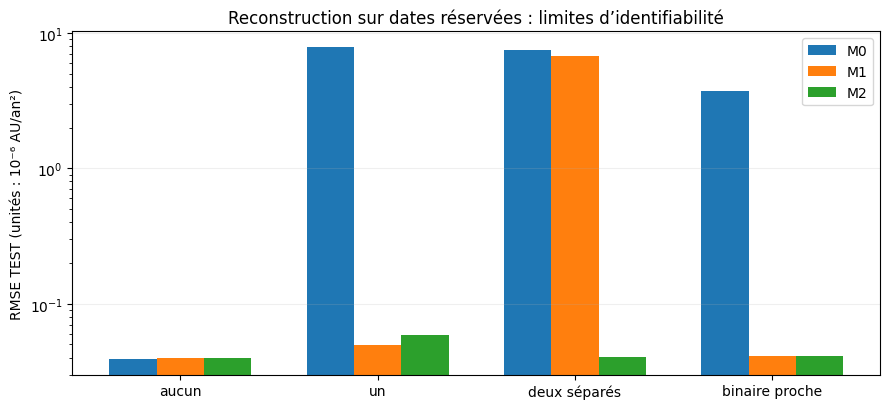

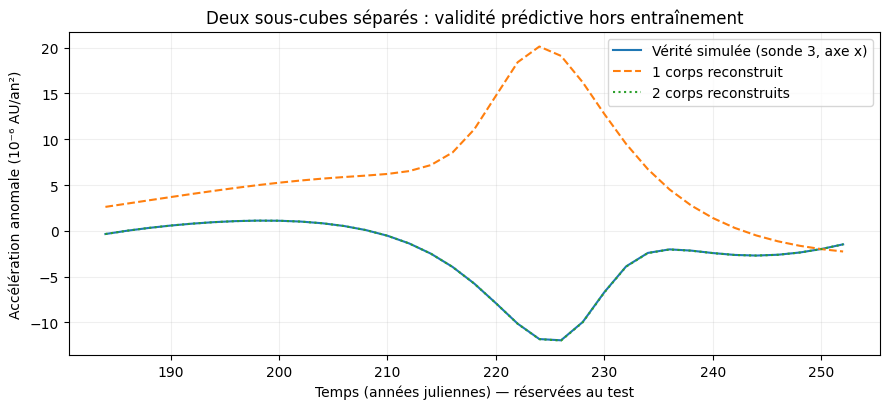

In [8]:
fig,ax=plt.subplots(figsize=(9,4.2))
labels=['aucun','un','deux séparés','binaire proche']
keys=list(SCENE_RESULT)
x=np.arange(len(keys))
width=.24
for k in (0,1,2):
    vals=[SCENE_RESULT[key]['fits'][k]['test_rmse'] for key in keys]
    ax.bar(x+(k-1)*width,vals,width,label=f'M{k}')
ax.set_yscale('log')
ax.set_xticks(x,labels)
ax.set_ylabel('RMSE TEST (unités : 10⁻⁶ AU/an²)')
ax.set_title('Reconstruction sur dates réservées : limites d’identifiabilité')
ax.legend()
ax.grid(axis='y',alpha=.2)
plt.tight_layout(); display(fig); plt.close(fig)

fig,ax=plt.subplots(figsize=(9,4.2))
ref=SCENE_TRUTH['S2_doubles_separes']
best1=model_accel(SCENE_RESULT['S2_doubles_separes']['fits'][1]['parameters'])
best2=model_accel(SCENE_RESULT['S2_doubles_separes']['fits'][2]['parameters'])
idx=N_TRAIN+np.arange(len(TEST_T))
ax.plot(TEST_T,ref[idx,2,0],label='Vérité simulée (sonde 3, axe x)')
ax.plot(TEST_T,best1[idx,2,0],label='1 corps reconstruit',linestyle='--')
ax.plot(TEST_T,best2[idx,2,0],label='2 corps reconstruits',linestyle=':')
ax.set_xlabel('Temps (années juliennes) — réservées au test')
ax.set_ylabel('Accélération anomale (10⁻⁶ AU/an²)')
ax.set_title('Deux sous-cubes séparés : validité prédictive hors entraînement')
ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); display(fig); plt.close(fig)

## Niveau 4 — Verdict scientifique et certificat de traçabilité

Les tests suivants vérifient la **cohérence et la reproductibilité** du protocole synthétique. Un résultat PASS n'établit ni existence d'une planète réelle ni supériorité de GVH sur la physique classique.

In [9]:
CHECKS={
  'train_test_separation':bool(TRAIN_T[-1]<TEST_T[0]),
  'positive_noise_and_correct_units':bool(SIGMA>0 and ACC_UNIT_SI>0),
  'negative_selects_zero':bool(SCENE_RESULT['S0_aucun']['preferred_model_count_from_train_BIC']==0),
  'single_selects_one':bool(SCENE_RESULT['S1_unique']['preferred_model_count_from_train_BIC']==1),
  'separated_pair_selects_two':bool(SCENE_RESULT['S2_doubles_separes']['preferred_model_count_from_train_BIC']==2),
  'close_pair_not_resolved':bool(SCENE_RESULT['S3_binaire_rapprochee']['preferred_model_count_from_train_BIC']==1),
  'separated_pair_holdout_gain_gt10':bool(S2_ERRORS['holdout_rmse_ratio_M1_over_M2']>10),
  'separated_pair_mass_error_lt5pct':bool(max(S2_ERRORS['relative_masses'])<.05),
  'separated_pair_radius_error_lt5pct':bool(max(S2_ERRORS['relative_radii'])<.05),
  'separated_pair_phase_error_lt0p03rad':bool(max(S2_ERRORS['phase_abs_errors_rad'])<.03),
  'sequential_hidden_second_selected':bool(SEQUENTIAL_PREFERRED==1),
  'sequential_mass_error_lt5pct':bool(SEQUENTIAL['second_parameter_errors']['relative_mass']<.05),
  'sequential_radius_error_lt5pct':bool(SEQUENTIAL['second_parameter_errors']['relative_radius']<.05),
  'sequential_phase_error_lt0p03rad':bool(SEQUENTIAL['second_parameter_errors']['phase_rad']<.03),
  'close_pair_internal_signal_below_noise':bool(CLOSE_BINARY['difference_to_noise_ratio']<.1),
  'robustness_noise_repetitions':bool(all(sum(x==data['expected_effective_count'] for x in data['selected_counts'])>=4
        for data in ROBUSTNESS.values())),
  'all_nonlinear_fits_succeeded':bool(all(f['success'] for row in SCENE_RESULT.values() for f in row['fits'])),
  'all_bic_values_finite':bool(all(np.isfinite(f['BIC_train']) for row in SCENE_RESULT.values() for f in row['fits'])),
}
for title,ok in CHECKS.items():print(('PASS' if ok else 'FAIL'),title)
assert all(CHECKS.values()), 'Le benchmark local n’a pas satisfait toutes les contraintes.'

REPORT={
 'notebook':RUN_NAME,
 'date_utc':datetime.now(timezone.utc).isoformat(),
 'status':'SYNTHETIC_HIERARCHICAL_INVERSE_LOCAL_PASS',
 'checks_passed':int(sum(CHECKS.values())),
 'checks_total':len(CHECKS),
 'checks':CHECKS,
 'scientific_novel_GVH_prediction':'BLOCKED',
 'real_observations_used':False,
 'dynamics':'prescribed circular Keplerian reference and Newtonian anomaly, not self-consistent N-body',
 'CHH_composition_is_not_dynamical_derivation':True,
 'inverse_models':'0 / 1 / 2 independent hidden circular point masses; 3 parameters each',
 'metric_train_selection':'BIC',
 'holdout_used_in_fit_or_selection':False,
 'sigma_acc_units':SIGMA,
 'acc_unit_m_s2':ACC_UNIT_SI,
 'train_times_years':TRAIN_T.tolist(),
 'holdout_times_years':TEST_T.tolist(),
 'inference_scenarios':SCENE_RESULT,
 'sequential_first_component_revealed_oracle':SEQUENTIAL,
 'binary_close_identifiability':CLOSE_BINARY,
 'resolved_pair_errors':S2_ERRORS,
 'robustness_selection':ROBUSTNESS,
 'generator_parameters_archived_for_audit_only':{'H1':H1_GENERATOR,'H2':H2_GENERATOR,'binary':BINARY_GENERATOR},
 'references':[
   'https://doi.org/10.1111/j.1365-2966.2011.18962.x',
   'https://doi.org/10.1051/0004-6361/202244633',
   'https://doi.org/10.3847/2041-8213/ae42cd'
 ],
 'open_locks':[
  'No independent real astrometric/radial-velocity data tested',
  'Input is acceleration residual, not directly measured positions',
  'Test bodies fixed on circular reference paths; dynamics not N-body self-consistent',
  'Only circular coplanar hidden-source inverse models evaluated',
  'Close binary is unidentifiable at the injected noise level and tested model class',
  'No GVH S_cand full coupled EOM solved or novel GVH predictions',
  'CHH-INVERSE-03 requires independent radius/spectroscopy/thermal data to infer physical type'
 ],
 'next_step':'GVH_CHH_INVERSE_03_Physical_Nature_and_Activity_Classification_Blind_Gate_FAST or realistic astrometric N-body gate'
}
report_path=Path.cwd()/(RUN_NAME+'_results.json')
report_path.write_text(json.dumps(REPORT,indent=2,ensure_ascii=False,default=lambda x:float(x) if isinstance(x,np.floating) else int(x)),encoding='utf-8')
print('\nVERDICT:',REPORT['status'],'|',len(CHECKS),'contrôles ; fichier :',report_path)
print('Limite : deux sous-cubes très proches peuvent rester un seul sous-cube EFFECTIF pour un observateur.')

PASS train_test_separation
PASS positive_noise_and_correct_units
PASS negative_selects_zero
PASS single_selects_one
PASS separated_pair_selects_two
PASS close_pair_not_resolved
PASS separated_pair_holdout_gain_gt10
PASS separated_pair_mass_error_lt5pct
PASS separated_pair_radius_error_lt5pct
PASS separated_pair_phase_error_lt0p03rad
PASS sequential_hidden_second_selected
PASS sequential_mass_error_lt5pct
PASS sequential_radius_error_lt5pct
PASS sequential_phase_error_lt0p03rad
PASS close_pair_internal_signal_below_noise
PASS robustness_noise_repetitions
PASS all_nonlinear_fits_succeeded
PASS all_bic_values_finite

VERDICT: SYNTHETIC_HIERARCHICAL_INVERSE_LOCAL_PASS | 18 contrôles ; fichier : /mnt/data/GVH_CHH_INVERSE_02_Hierarchical_Hidden_Subcube_Recovery_FAST_results.json
Limite : deux sous-cubes très proches peuvent rester un seul sous-cube EFFECTIF pour un observateur.
